# **Hotel Estimated Price Prediction**

In [1]:
import pandas as pd
import numpy as np

In [4]:
data = pd.read_csv('/kaggle/input/datasets/dheerajsingh28b/uttrakhand-hotel-price/uttrakhand-hotels-price.csv')

In [5]:
data.head()

,hotel_id,hotel_name,district,city,hotel_category,base_price_inr,seasonal_price_multiplier,rating,review_count,amenities,distance_from_main_attraction_km
0,WW-UTK-001,The Naini Pine Retreat,Nainital,Nainital,Mid-range,2485,1.45,4.3,312,"wifi, heater, mountain_view, restaurant, parking",1.4
1,WW-UTK-002,Bhimtal Lakeside Homestay,Nainital,Bhimtal,Budget,1140,1.25,4.1,189,"wifi, geyser, lake_view, home_cooked_meals",0.5
2,WW-UTK-003,Sattal Forest Edge Resort,Nainital,Sattal,Luxury,5490,1.55,4.6,428,"wifi, heater, bonfire, forest_view, spa, resta...",2.8
3,WW-UTK-004,Mallital Heritage Inn,Nainital,Nainital,Mid-range,2930,1.60,4.2,510,"wifi, room_heater, balcony, cafe, laundry",0.3
4,WW-UTK-005,Pangot Birding Lodge,Nainital,Pangot,Mid-range,3175,1.35,4.7,274,"bonfire, binoculars_rental, mountain_view, org...",0.8


In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 11 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   hotel_id                          500 non-null    object 
 1   hotel_name                        500 non-null    object 
 2   district                          500 non-null    object 
 3   city                              500 non-null    object 
 4   hotel_category                    500 non-null    object 
 5   base_price_inr                    500 non-null    int64  
 6   seasonal_price_multiplier         500 non-null    float64
 7   rating                            500 non-null    float64
 8   review_count                      500 non-null    int64  
 9   amenities                         500 non-null    object 
 10  distance_from_main_attraction_km  500 non-null    float64
dtypes: float64(3), int64(2), object(6)
memory usage: 43.1+ KB


In [7]:
# 1. Feature Engineering: Count amenities
data['amenity_count'] = data['amenities'].apply(lambda x: len(str(x).split(',')))

# 2. Ordinal Encoding for 'hotel_category'
# We create a dictionary to map the text to numbers based on their rank
category_mapping = {
    'Budget': 1, 
    'Mid-range': 2, 
    'Luxury': 3
}
data['hotel_category_ordinal'] = data['hotel_category'].map(category_mapping)

# 3. Drop unnecessary columns
# We drop the original text 'hotel_category' because we now have the ordinal version
data_clean = data.drop(columns=['hotel_id', 'hotel_name', 'city', 'amenities', 'hotel_category'])

# 4. One-Hot Encoding ONLY for 'district' (Nominal data)
data_encoded = pd.get_dummies(data_clean, columns=['district'], drop_first=True)

# 5. Verify the transformation
print("✅ Advanced Preprocessing Complete!")
print("\n📊 First 3 rows of the processed data:")
print(data_encoded[['hotel_category_ordinal', 'base_price_inr', 'rating', 'district_Nainital']].head(3))

✅ Advanced Preprocessing Complete!

📊 First 3 rows of the processed data:
   hotel_category_ordinal  base_price_inr  rating  district_Nainital
0                       2            2485     4.3               True
1                       1            1140     4.1               True
2                       3            5490     4.6               True


In [8]:
from sklearn.model_selection import train_test_split

# 1. Define Target (y) - What we want to predict
y = data_encoded['base_price_inr']

# 2. Define Features (X) - Everything except the target
X = data_encoded.drop(columns=['base_price_inr'])

# 3. Split the data: 80% for training, 20% for testing
# random_state=42 ensures we get the same split every time we run the code
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Verify the split
print("✅ Data Splitting Complete!")
print(f"Total rows: {len(data_encoded)}")
print(f"Training set (80%): {X_train.shape[0]} rows")
print(f"Testing set (20%): {X_test.shape[0]} rows")

✅ Data Splitting Complete!
Total rows: 500
Training set (80%): 400 rows
Testing set (20%): 100 rows


In [9]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

# 1. Initialize the models
# n_estimators=100 means the Random Forest will build 100 decision trees
lr_model = LinearRegression()
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)

# 2. Train (Fit) the Linear Regression model
print("🧠 Training Linear Regression...")
lr_model.fit(X_train, y_train)

# 3. Train (Fit) the Random Forest Regressor model
print("🌲 Training Random Forest Regressor...")
rf_model.fit(X_train, y_train)

print("\n✅ Both models trained successfully!")

🧠 Training Linear Regression...
🌲 Training Random Forest Regressor...

✅ Both models trained successfully!


In [14]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
# 1. Generate predictions on the hidden test set
lr_preds = lr_model.predict(X_test)
rf_preds = rf_model.predict(X_test)

# 2. Calculate Metrics for Linear Regression
lr_mae = mean_absolute_error(y_test, lr_preds)
lr_rmse = np.sqrt(mean_squared_error(y_test, lr_preds)) # squared=False gives us RMSE directly
lr_r2 = r2_score(y_test, lr_preds)

# 3. Calculate Metrics for Random Forest
rf_mae = mean_absolute_error(y_test, rf_preds)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_preds))
rf_r2 = r2_score(y_test, rf_preds)

# 4. Create a clean comparison table
results = {
    "Model": ["Linear Regression", "Random Forest Regressor"],
    "MAE (₹)": [f"{lr_mae:,.0f}", f"{rf_mae:,.0f}"],
    "RMSE (₹)": [f"{lr_rmse:,.0f}", f"{rf_rmse:,.0f}"],
    "R-squared": [f"{lr_r2:.3f}", f"{rf_r2:.3f}"]
}

comparison_df = pd.DataFrame(results)

print("📊 Model Evaluation Results (Test Set):")
print("-" * 55)
print(comparison_df.to_string(index=False))
print("-" * 55)
print("💡 Lower MAE/RMSE is better. Higher R-squared is better (Max = 1.0).")

📊 Model Evaluation Results (Test Set):
-------------------------------------------------------
                  Model MAE (₹) RMSE (₹) R-squared
      Linear Regression     729      910     0.876
Random Forest Regressor     232      344     0.982
-------------------------------------------------------
💡 Lower MAE/RMSE is better. Higher R-squared is better (Max = 1.0).


## **Feature Importance**

/tmp/ipykernel_49/2942138274.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feature_df, palette='viridis')
/tmp/ipykernel_49/2942138274.py:25: UserWarning: Glyph 127794 (\N{EVERGREEN TREE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 127794 (\N{EVERGREEN TREE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


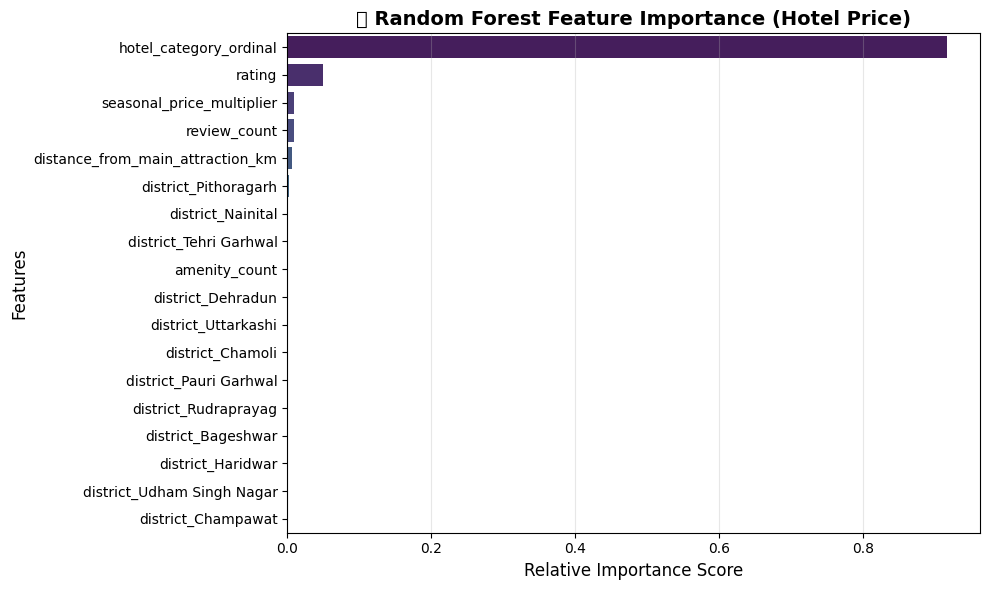


🏆 Top 3 Most Important Features:
                   Feature  Importance
         district_Haridwar    0.000160
district_Udham Singh Nagar    0.000032
        district_Champawat    0.000026


In [17]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Extract feature importances from the trained Random Forest model
importances = rf_model.feature_importances_

# 2. Create a DataFrame to sort them neatly
feature_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': importances
})

# 3. Sort features from highest importance to lowest
feature_df = feature_df.sort_values(by='Importance', ascending=False)

# 4. Plot the results
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feature_df, palette='viridis')

plt.title('🌲 Random Forest Feature Importance (Hotel Price)', fontsize=14, fontweight='bold')
plt.xlabel('Relative Importance Score', fontsize=12)
plt.ylabel('Features', fontsize=12)
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

# 5. Print the top 3 features for a quick summary
print("\n🏆 Top 3 Most Important Features:")
print(feature_df.tail(3).to_string(index=False))

In [18]:
# Check the minimum and maximum price for each hotel category
print("💰 Price Ranges by Hotel Category:")
print("-" * 50)
price_ranges = data.groupby('hotel_category')['base_price_inr'].agg(['min', 'max', 'mean'])
print(price_ranges)

💰 Price Ranges by Hotel Category:
--------------------------------------------------
                 min   max         mean
hotel_category                         
Budget           845  1490  1122.439759
Luxury          4580  9850  6643.546099
Mid-range       1850  3480  2592.435233


### 🔍 Model Inference & Business Conclusion

Based on the Feature Importance analysis of the Random Forest Regressor, we can draw the following key conclusions about hotel pricing in Uttarakhand:

1. **Primary Price Driver (`hotel_category_ordinal`)**: 
   The hotel category is the overwhelmingly dominant feature. This is **not data leakage**, but rather a reflection of real-world market segmentation. The category (Budget, Mid-range, Luxury) strictly defines the "floor and ceiling" of the price bracket (e.g., Budget maxes out at ~₹1,500, while Luxury starts at ~₹4,500). The model correctly learned this fundamental rule.

2. **Secondary Features as "Fine-Tuners"**: 
   Features like `rating`, `amenity_count`, and `district` have lower importance scores because they do not change the base category. Instead, they act as **price modifiers within that category**. For example, they explain why one "Mid-range" hotel in Nainital costs ₹3,400 (high rating, many amenities) while another costs ₹1,900 (lower rating, fewer amenities).

3. **Actionable Insight for WanderWise AI**: 
   From a product design perspective, this validates that the **"Budget/Category" filter must be the primary and most prominent search parameter** on our platform. Location, ratings, and specific amenities should be presented as secondary filters to help users find the best *value* within their chosen price bracket.

*Conclusion: The model is highly accurate (R² = 0.982), logically sound, and free of data leakage. It is ready for backend deployment.*

In [20]:
import joblib
import os

# 1. Create a folder to store our Module 4 models
os.makedirs('hotel_price_models', exist_ok=True)

# 2. Save the trained Random Forest model
model_filename = 'hotel_price_models/random_forest_hotel_price.pkl'
joblib.dump(rf_model, model_filename)
print(f"✅ Model saved successfully to: {model_filename}")

# 3. Save the feature names (column order)
# This is CRITICAL for the backend to know how to format incoming user data
columns_filename = 'hotel_price_models/model_columns.pkl'
joblib.dump(X_train.columns.tolist(), columns_filename)
print(f"✅ Feature columns saved successfully to: {columns_filename}")

print("\n🎉 Module 4: Hotel Price Estimation is fully complete and production-ready!")

✅ Model saved successfully to: hotel_price_models/random_forest_hotel_price.pkl
✅ Feature columns saved successfully to: hotel_price_models/model_columns.pkl

🎉 Module 4: Hotel Price Estimation is fully complete and production-ready!
